# How to create an agent to balance a pole vertically on a moving cart?


<center>
<img src="https://roboticdreams.wordpress.com/wp-content/uploads/2015/05/broom-balancing.jpg" width="400">
</center>

## CartPole Agent

<center>
<img src="https://miro.medium.com/max/405/1*wlhePk4me-s334nGw8mHqg.gif" width="700">
</center>


## Forces in play:

<center>
<img src="https://github.com/NimritaKoul/ReinforcementLearning31Oct2026/blob/main/cartpoleforces.png?raw=true" width="700">
</center>



In [1]:
from IPython.display import HTML

# Direct raw link to the MP4 file on GitHub
video_url = "https://raw.githubusercontent.com/NimritaKoul/ReinforcementLearning31Oct2026/main/cartpole.mp4"

# Embed and display the video
HTML(f'''
<video width="1000" controls autoplay loop>
    <source src="{video_url}" type="video/mp4">
    Your browser does not support the video tag.
</video>
''')

# The Cart Pole Balancing Problem

The **Cart Pole** (also known as the *Inverted Pendulum* or *system of cart and pole*) is one of the classic benchmarking problems in control theory and Reinforcement Learning (RL).

### 1. The Core Objective

The objective: **keep a pole balanced upright** on top of a cart by applying horizontal force impulses to push the cart either to the **Left** or to the **Right**.

### 2. State Space (Observations)

At any moment, the environment's state is fully represented by a vector of **four continuous values**:

1. **Cart Position ($x$):** The horizontal location of the cart on the track (in our code it ranges from $-4.8$ to $+4.8$).

2. **Cart Velocity ($ȩ$):** How fast the cart is sliding left or right.

3. **Pole Angle ($\theta$):** The tilt of the pole relative to the vertical axis (measured in radians, roughly within $\pm 24^\circ$ or $\pm 0.4188$ rad).

4. **Pole Angular Velocity ($\dot{\theta}$):** The rotational speed at which the pole is falling or uprighting itself.

### 3. Action Space

The agent can choose one of **two discrete actions** at each step:
* `0`: Push the cart **Left**
* `1`: Push the cart **Right**

### 4. Reward & Termination Conditions
* **Reward:** The agent receives a reward of $+1.0$ for every step the pole remains upright.
* **Termination:** An episode ends (meaning the agent fails) if:
  * The pole tilts too far: $|\theta| > 12^\circ$ (or $\approx 0.2095$ radians).
  * The cart moves off the screen edges: $|x| > 2.4$ units.

# Implementation of RL based solution to CartPole V1 using Off-Policy Monte Carlo Control on CartPole-v1

In this notebook, we will train an autonomous agent to balance a pole on a moving cart (the classic physics control problem known as CartPole-v1) using RL.


We will walk through following steps:

1. Set up virtual display to run and render graphical simulation environments in a headless cloud server environment such as Google Colab.

2. We inspect the physical dynamics of the environment of Cart Pole. The environment has four states (two positions, two velocities) and two possible actions (push left or push right).

3. We discretize continuous state variables by rounding them to one decimal place.

4. We establish a baseline by showing how poorly a random strategy performs (it survives only 21 frames on an average)

5. We implement a model-free RL algorithm known as Off-Policy Monte Carlo Control with Weighted Importance Sampling to learn the optimal action-value table (Q) from trial-and-error gameplay.

6. We validate agent's progress during training to watch its survival capabilities increase.

7. Visualize final learned policy that shows how the agent chooses actions to balance the pole depending on its angle and speed.


## Install Xvfb (X Virtual Framebuffer) and Python OpenGL.

Since Google Colab runs on a headless cloud server (a machine without a physical monitor), standard GUI-based renderings like Gym's screen visualization would crash without a virtual display. Xvfb simulates a graphical monitor in the background to capture frames and render environment screens.

In [2]:
!apt-get install -y xvfb python-opengl > /dev/null 2>&1

## The next cell installs gymnasium (the standard API library for reinforcement learning environments) and pyvirtualdisplay.

- gymnasium provides the CartPole-v1 simulation environment.
- pyvirtualdisplay acts as a Python wrapper wrapper for the xvfb virtual screen step, allowing Python code to control and launch the virtual display server from within Google Colab which is running in a headless cloud server.

In [1]:
!pip install gymnasium pyvirtualdisplay > /dev/null 2>&1

## Required imports

In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from IPython import display as ipythondisplay
from collections import defaultdict
import math

## Create a virtual display object

In [4]:
from pyvirtualdisplay import Display
display = Display(visible=0, size=(400, 300))
display.start()

## Creates the CartPole-v1 reinforcement learning environment instance.

Iterations that were run: 14


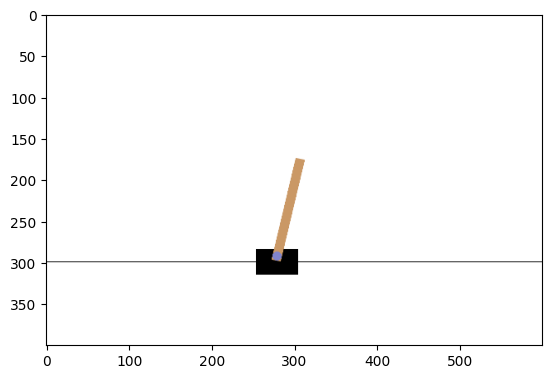

In [6]:
#Creates the CartPole-v1 reinforcement learning environment instance.
#Specifying render_mode="rgb_array" configures the environment to return frames
#as raw pixel arrays (RGB images) when rendering, which allows us to draw it manually.
env = gym.make("CartPole-v1", render_mode="rgb_array")

#Resets the environment to its initial random state and returns the first observation.
env.reset()

#Captures the first image frame of the environment (the initial cart and pole position) so we have a starting frame to display.
prev_screen = env.render()
plt.imshow(prev_screen)

#Runs for a maximum of 50,000 steps to simulate the cartpole system.
for i in range(50000):
  #Selects a completely random action from the environment's action space (either 0 to push left or 1 to push right).
  action = env.action_space.sample()
  print("step i",i,"action=",action)

  #Applies the chosen action to the environment.
  #obs: The new state (position, velocity, angle, angular velocity).
  #reward: The reward for surviving the step (always 1.0 in CartPole).
  #terminated: True if the pole fell too far or the cart moved out of bounds.
  #info: A dictionary containing auxiliary diagnostic information.
  obs, reward, terminated, truncated, info = env.step(action)

  # The episode is over
  done = terminated or truncated
  print("obs=",obs,"reward=",reward,"done=",done,"info=",info)

  #Captures the new updated frame of the environment after the action was taken.
  screen = env.render()

  plt.imshow(screen)

  #Clears whatever was previously printed or displayed in the output area
  ipythondisplay.clear_output(wait=True)

  #Renders and displays the active Matplotlib figure
  ipythondisplay.display(plt.gcf())

  if done:
    break

ipythondisplay.clear_output(wait=True)
env.close()
print("Iterations that were run:",i)

## Print the state space

Prints the limits and shape of this state space.

In this case, it prints a 4-dimensional box boundary (Box(...)) representing the minimum and maximum allowable values for:

- Cart Position (ranging from -4.8 to 4.8)

- Cart Velocity (ranging from -inf to inf)

- Pole Angle (ranging from -0.4188 to 0.4188 radians, or about ±24°)

- Pole Angular Velocity (ranging from -inf to inf)

In [7]:
stateSpaceSize = env.observation_space
print(stateSpaceSize)

Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)


## prints the number of allowed actions in the environment

In [8]:
actionSpaceSize = env.action_space.n
print(actionSpaceSize)

2


## Choose a random action, execute it and print the reward, observation etc.

In [9]:
env.reset()
action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(action)
done = terminated or truncated
print("obs=",obs,"reward=",reward,"done=",done,"info=",info)

obs= [ 0.02357747 -0.16009933  0.02666607  0.30994248] reward= 1.0 done= False info= {}


## Helper function to round the state to a whole number

In [10]:
def round_state(state) :
  for i in range(len(state)) :
    state[i] = round(state[i],1)
  return state

## Create a Q-table, Execute a random action

Output means this:

- State representation: The rounded state values for (Cart Position, Cart Velocity, Pole Angle, Pole Angular Velocity) are registered in a tuple as (0.0, -0.2, 0.0, 0.3).

- Values: For this specific state, action 0 (Left) has an assigned value of 1.0, while action 1 (Right) is uninitialized at 0.0.

In [11]:
# Reset env to start a new episode
env.reset()

# chose a random action 0 or 1
action = env.action_space.sample()

# execute that action
obs, reward, terminated, truncated, info = env.step(action)

# round each parameter of the observation vector, converts the result into a hasable tuple
state = tuple(round_state(obs))

# initialize an empty action-value dictionary Q
Q = defaultdict(lambda: np.zeros(actionSpaceSize))

# assign 1 to specific state-action pair we just encountered
Q[state][action] = 1
Q

defaultdict(<function __main__.<lambda>()>,
            {(np.float32(-0.0),
              np.float32(0.2),
              np.float32(-0.0),
              np.float32(-0.3)): array([0., 1.])})

### Q-Table

A Q-table is table in memory that a Reinforcement Learning agent uses to figure out the best move to make in a game or environment. The "Q" stands for Quality, meaning the table measures the **quality or long-term value** of taking a specific action in a specific situation.


<center>
<img src="https://cdn.prod.website-files.com/67a1e6de2f2eab2e125f8b9a/67be11b98129a4ffcfae3290_rl3.png" width="700">
</center>


### In our Q-Table, we just assigned the action "Right" (move right) a value of 1 for the current state, a the action "Left" a value of 0.

<center>
<img src="https://raw.githubusercontent.com/NimritaKoul/ReinforcementLearning31Oct2026/refs/heads/main/SampleQTable.png" width="700">
</center>

## Let us set up a baseline performance score using a completely random policy (agent chooses a random action at each step)

We will see how many steps the pole can be balanced on the cart on an average  before falling over.

- We run the CartPole simulation over 100 distinct episodes.
- Inner Step: For each step, it samples a purely random action (push Left or Right).
- Whenever the game ends (done), it adds the number of survived steps (i) to a running sum (avg_iter).
- Averages this sum over the 100 episodes.



In [12]:
env = gym.make("CartPole-v1")
env.reset()
avg_iter = 0

for k in range(100) :
  env.reset()
  for i in range(10000):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    if done:
      avg_iter = avg_iter + i
      break

  env.close()

avg_iter = avg_iter / 100
print("Average iterations that were run:",avg_iter)

Average iterations that were run: 18.62


## This funtion generate_episode(env, episode) generates a full gameplay sequence (episode) using a completely random behavior policy.

- State Initialization: It resets the environment, retrieves the starting state, and rounds the state values using the round_state function.
- Simulation Loop: It steps through the game up to 50,000 times. During each step, it records the current state, action taken, and reward received to a list (episode).
- Exploration: Actions are sampled at random (np.random.choice) in each step to ensure that the environment is thoroughly explored.
- Termination: The loop breaks and finishes saving the sequence as soon as the pole falls over or is truncated (done = True). This generated episode list is later used by the Off-Policy Monte Carlo Control algorithm to update the Q-table.

In [13]:
def generate_episode(env,episode) :
  state, _ = env.reset()
  state = tuple(round_state(state))
  action = np.random.choice(np.arange(actionSpaceSize))
  for i in range(50000):
    next_state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    next_state = tuple(round_state(next_state))
    next_action = np.random.choice(np.arange(actionSpaceSize))

    episode.append((state, action, reward))
    state = next_state
    action = next_action
    if done:
      break

# Greedy Policy

## We will next create a validation helper function to evaluate how well our current action-value table (Q) performs over 100 simulation games using greedy policy based on Q (without using any exploration).

- Creates a fresh instance of the CartPole-v1 environment.
- Runs the evaluation over 100 independent episodes.
- Greedy Action Selection: In every step, instead of choosing random actions, it looks at the current rounded state and greedily selects the best action learned so far using np.argmax(Q[state]).
- Updating and Termination: It steps the environment using this action, updates the current state, and breaks the inner loop when the pole falls (done=True).
- Finally, it sums up the total number of frames balanced, divides it by 100, and returns the average survival steps achieved by our learned policy.

This function is used inside our Off-Policy Monte Carlo algorithm (off_MC_control) every 2,000 training episodes to track and print how the agent's performance improves over time.

In [14]:
def test_MC(Q) :
  env = gym.make("CartPole-v1")
  env.reset()
  avg_iter = 0

  for k in range(100) :
    state, _ = env.reset()
    state = tuple(round_state(state))

    for i in range(10000):
      action = np.argmax(Q[state]) #Choose the action with maximum Q value
      obs, reward, terminated, truncated, info = env.step(action)
      done = terminated or truncated
      next_state = tuple(round_state(obs))
      state = next_state

      if done:
         break

    env.close()
    avg_iter = avg_iter + i

  avg_iter = avg_iter / 100
  #print("Average iterations that were run:",avg_iter)
  return avg_iter

## Implement the Off-Policy Monte Carlo Control (using Weighted Importance Sampling) algorithm to train our CartPole agent.



In [15]:
# env, max number of episodes and discount factor
def off_MC_control(env, max_episodes,gamma):
  ## initial action-value function Q, cumulative sum of importance weignts C for all state-action pairs
  Q = defaultdict(lambda: np.zeros(actionSpaceSize))
  C = defaultdict(lambda: np.zeros(actionSpaceSize))

  ## Training Loop
  for eps in range(max_episodes+1) :
    # behaviour policy b
    b = np.ones(actionSpaceSize) / actionSpaceSize
    # generate an episode
    episode = []#to store the sequence of states, actions, rewards for current episode
    generate_episode(env,episode)#run one complete simulation game using random behaviour policy

    G = 0 #initial value of cumuative discounted return
    W = 1 #initial value of importance sampling weight

    # loop for each episode backwards, t = T-1,T-2,...,0
    # Monte Carlo updates are computed backwards in chronological order
    for t in range(len(episode)-1, -1, -1):
      #unpack state visited, aciton taken, reward received at time t
      state, action, reward = episode[t]

      #Update discounted return using Bellman equation
      G = gamma * G + reward # gamma * G + R_{t+1}

      #add current importance weight W to running sum of weights C(s,a) for this state-action pair
      C[state][action] = C[state][action] + W  # C + W

      # Do weighted importance sampling update for Q(s,a), moves estimated Q closer to observed return G
      # scaled by ratio of current weight over cumulative weights
      Q[state][action] = Q[state][action] + (G-Q[state][action])*(W/C[state][action])

      # identify optimal aciton according to greedy policy (action with max Q for s)
      pi_S_t = np.argmax(Q[state])

      # if random action we too does not match the action our target greedy policy would
      # have chosen (pi_S_t), stop updating this episode
      if action !=  pi_S_t:
        break

      # update importance sampling weight for next backward step.
      W = W * 1./b[action]

    # every 2000 episodes, check progress
    if eps % 2000 == 0:
      #run 100 evaluation games using current Q table in greedy mode to calc avg performance
      avg_iter = test_MC(Q)
      print("For episode",eps,"Average is",avg_iter)

  return Q # return final trained action-value (Q) table when all episodes are completed.

## Training the agent using above off policy Monte Carlo function to learn Q

In [16]:
Q = off_MC_control(env, 20000, 1)

For episode 0 Average is 17.27
For episode 2000 Average is 34.99
For episode 4000 Average is 39.29
For episode 6000 Average is 35.42
For episode 8000 Average is 46.87
For episode 10000 Average is 45.39
For episode 12000 Average is 40.89
For episode 14000 Average is 44.17
For episode 16000 Average is 44.45
For episode 18000 Average is 43.34
For episode 20000 Average is 43.03


## Print the number of unique states visited during Q -learning

In [17]:
unique_states_count = len(Q.keys())
print(f"Total number of unique states visited in Q: {unique_states_count}")

Total number of unique states visited in Q: 9896


## Display the environment

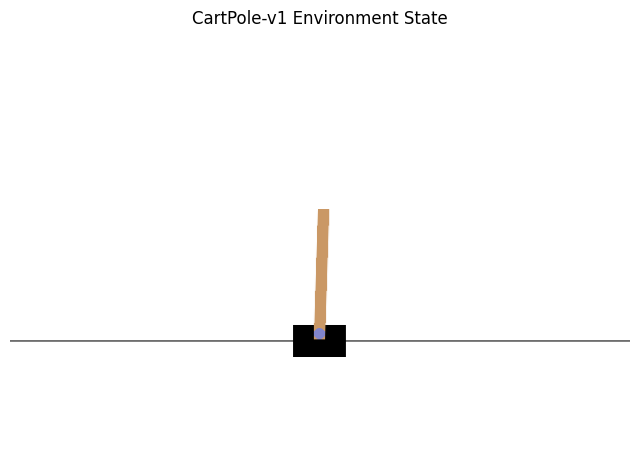

In [18]:
import matplotlib.pyplot as plt

# Recreate or use existing environment with rgb_array render mode
env = gym.make("CartPole-v1", render_mode="rgb_array")
env.reset()

# Capture and plot the starting frame
frame = env.render()
plt.figure(figsize=(8, 6))
plt.imshow(frame)
plt.title("CartPole-v1 Environment State")
plt.axis("off")
plt.show()

env.close()

## Display learned policy map



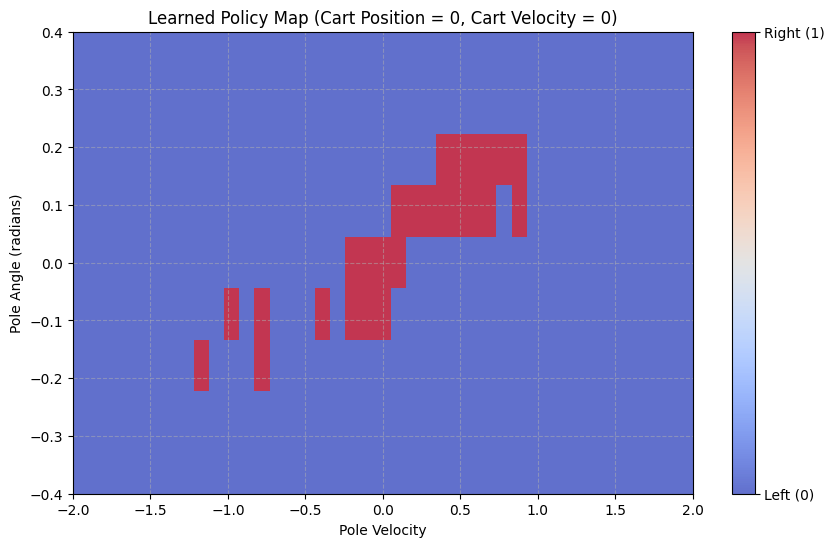

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Define ranges for Pole Angle and Pole Velocity (rounded to 1 decimal place to match round_state)
pole_angles = np.arange(-0.4, 0.5, 0.1)
pole_velocities = np.arange(-2.0, 2.1, 0.1)

policy_grid = np.zeros((len(pole_angles), len(pole_velocities)))

# We fix Cart Position and Cart Velocity to 0.0 to slice the 4D state space
fixed_cart_pos = 0.0
fixed_cart_vel = 0.0

# Create a 2D grid of values for remaining two active variables, pole angles and pole velocities
for i, angle in enumerate(pole_angles):
    for j, vel in enumerate(pole_velocities):
        # Construct state matching the rounded format in Q
        state = (np.float32(round(fixed_cart_pos, 1)),
                 np.float32(round(fixed_cart_vel, 1)),
                 np.float32(round(angle, 1)),
                 np.float32(round(vel, 1)))

        # Retrieve the best action from Q (defaults to 0 if state was never visited)
        policy_grid[i, j] = np.argmax(Q[state])

# Plot the policy decision boundary
plt.figure(figsize=(10, 6))
plt.imshow(policy_grid, extent=[pole_velocities.min(), pole_velocities.max(), pole_angles.min(), pole_angles.max()],
           aspect='auto', origin='lower', cmap='coolwarm', alpha=0.8)

# Formatting plot
cbar = plt.colorbar(ticks=[0, 1])
cbar.set_ticklabels(['Left (0)', 'Right (1)'])
plt.xlabel('Pole Velocity')
plt.ylabel('Pole Angle (radians)')
plt.title('Learned Policy Map (Cart Position = 0, Cart Velocity = 0)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Benchmark: Trained Greedy Policy vs. Random Policy

To quantitatively evaluate our learning success, we run both our trained greedy policy (using our $Q$-table) and a baseline random policy over 100 episodes. We then compare their survival statistics (Mean, Min, Max, and Standard Deviation of steps) and visualize them side-by-side.

=== PERFORMANCE BENCHMARK ===
Random Agent  | Mean Steps: 23.14 ± 11.76 | Min: 9.0 | Max: 64.0
Trained Agent | Mean Steps: 45.97 ± 16.05 | Min: 17.0 | Max: 122.0


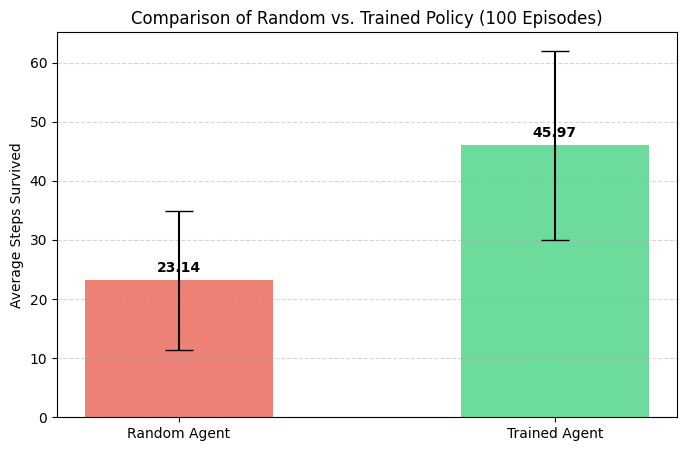

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Number of episodes for evaluation
n_eval_episodes = 100
eval_env = gym.make("CartPole-v1")

# 1. Evaluate Random Agent
random_rewards = []
for _ in range(n_eval_episodes):
    eval_env.reset()
    episode_reward = 0
    for step in range(10000):
        action = eval_env.action_space.sample()
        _, reward, terminated, truncated, _ = eval_env.step(action)
        episode_reward += reward
        if terminated or truncated:
            break
    random_rewards.append(episode_reward)

# 2. Evaluate Trained Greedy Agent
trained_rewards = []
for _ in range(n_eval_episodes):
    state, _ = eval_env.reset()
    state = tuple(round_state(state))
    episode_reward = 0
    for step in range(10000):
        action = np.argmax(Q[state])
        obs, reward, terminated, truncated, _ = eval_env.step(action)
        episode_reward += reward
        state = tuple(round_state(obs))
        if terminated or truncated:
            break
    trained_rewards.append(episode_reward)

eval_env.close()

# Compute Statistics
mean_rand, std_rand = np.mean(random_rewards), np.std(random_rewards)
mean_train, std_train = np.mean(trained_rewards), np.std(trained_rewards)

print("=== PERFORMANCE BENCHMARK ===")
print(f"Random Agent  | Mean Steps: {mean_rand:.2f} ± {std_rand:.2f} | Min: {np.min(random_rewards)} | Max: {np.max(random_rewards)}")
print(f"Trained Agent | Mean Steps: {mean_train:.2f} ± {std_train:.2f} | Min: {np.min(trained_rewards)} | Max: {np.max(trained_rewards)}")

# Plot the comparative bar chart
labels = ['Random Agent', 'Trained Agent']
means = [mean_rand, mean_train]
stds = [std_rand, std_train]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, means, yerr=stds, align='center', alpha=0.7, color=['#e74c3c', '#2ecc71'], ecolor='black', capsize=10, width=0.5)
plt.ylabel('Average Steps Survived')
plt.title('Comparison of Random vs. Trained Policy (100 Episodes)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add values on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.2f}", ha='center', va='bottom', fontweight='bold')

plt.show()